<a href="https://colab.research.google.com/github/Hotmandooo/-zero.ipynb/blob/main/tiefigter_%EB%A1%9C%EA%B3%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [8]:
def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

In [24]:
def draw_rectangle(ax, p1, p2, p3, p4, color='#1B78FF'):
    my_polygon = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor=color, linewidth=0.6)
    ax.add_patch(my_polygon)

In [25]:
def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_gemini_exact(ax, p1, p2, p3, p4)

In [26]:
def get_exact_gemini_color(x, y, R):
    c_blue   = np.array([0.12, 0.50, 1.00])
    c_red    = np.array([0.98, 0.24, 0.28])
    c_orange = np.array([0.98, 0.48, 0.16])
    c_yellow = np.array([0.98, 0.75, 0.06])
    c_lime   = np.array([0.55, 0.84, 0.28])
    c_green  = np.array([0.02, 0.76, 0.42])
    c_purple = np.array([0.52, 0.42, 0.85])

    nx = x / R
    ny = y / R

    rgb = c_blue.copy()

    if ny > 0:
        w_top = (ny ** 1.45) * max(0.0, 1.0 - max(0.0, nx) * 1.3)
        w_top = min(1.0, w_top)
        w_purp = 4.0 * w_top * (1.0 - w_top) * max(0.0, 1.0 + nx) * 0.45
        rgb = (1.0 - w_top - w_purp) * rgb + w_top * c_red + w_purp * c_purple

    if ny < 0:
        w_bot = ((-ny) ** 1.45) * max(0.0, 1.0 - max(0.0, nx) * 1.3)
        w_bot = min(1.0, w_bot)
        rgb = (1.0 - w_bot) * rgb + w_bot * c_green

    if nx < 0:
        w_left = ((-nx) ** 1.25)
        w_left = min(1.0, w_left)

        if ny >= 0:
            t = min(1.0, ny / (1.0 + nx + 0.001))
            if t < 0.5:
                s = t * 2.0
                left_c = (1.0 - s) * c_yellow + s * c_orange
            else:
                s = (t - 0.5) * 2.0
                left_c = (1.0 - s) * c_orange + s * c_red
        else:
            t = min(1.0, (-ny) / (1.0 + nx + 0.001))
            if t < 0.5:
                s = t * 2.0
                left_c = (1.0 - s) * c_yellow + s * c_lime
            else:
                s = (t - 0.5) * 2.0
                left_c = (1.0 - s) * c_lime + s * c_green

        rgb = (1.0 - w_left) * rgb + w_left * left_c

    return (min(1.0, max(0.0, rgb[0])), min(1.0, max(0.0, rgb[1])), min(1.0, max(0.0, rgb[2])))

def draw_gemini_exact(ax, p1, p2, p3, p4):
    R = 820.0
    step = 18.0
    s = (step / LEN) * 1.15

    b1 = scale(p1, s, s)
    b2 = scale(p2, s, s)
    b3 = scale(p3, s, s)
    b4 = scale(p4, s, s)

    for x in np.arange(0, R, step):
        for y in np.arange(0, R, step):
            if (x / R) ** 0.58 + (y / R) ** 0.58 <= 1.0 and (x * x + y * y <= (R * 0.96) ** 2):
                q1 = translate(b1, x, y)
                q2 = translate(b2, x, y)
                q3 = translate(b3, x, y)
                q4 = translate(b4, x, y)
                draw_rectangle(ax, q1, q2, q3, q4, color=get_exact_gemini_color(x, y, R))

                ry1 = reflect_y(q1)
                ry2 = reflect_y(q2)
                ry3 = reflect_y(q3)
                ry4 = reflect_y(q4)
                draw_rectangle(ax, ry1, ry2, ry3, ry4, color=get_exact_gemini_color(-x, y, R))

                ro1 = reflect_origin(q1)
                ro2 = reflect_origin(q2)
                ro3 = reflect_origin(q3)
                ro4 = reflect_origin(q4)
                draw_rectangle(ax, ro1, ro2, ro3, ro4, color=get_exact_gemini_color(-x, -y, R))

                rx1 = reflect_x(q1)
                rx2 = reflect_x(q2)
                rx3 = reflect_x(q3)
                rx4 = reflect_x(q4)
                draw_rectangle(ax, rx1, rx2, rx3, rx4, color=get_exact_gemini_color(x, -y, R))

In [27]:
def translate(p, dx, dy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_yx(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

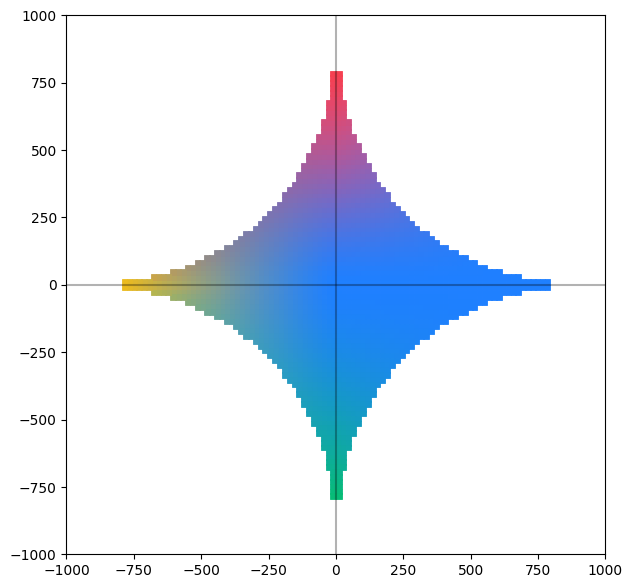

In [28]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()